<a href="https://colab.research.google.com/github/aleakucing/Pembelajaran-Memsin/blob/main/JS08/JS08_Assigment02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#0. Instalasi library
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Cek ketersediaan HDBSCAN
try:
    import hdbscan
    HDBSCAN_MODEL = hdbscan.HDBSCAN
except ImportError:
    from sklearn.cluster import HDBSCAN
    HDBSCAN_MODEL = HDBSCAN

sns.set_theme(style="whitegrid")

In [3]:
# 1.Load dataset Iris
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Tampilkan ringkasan data
df_iris = pd.DataFrame(X, columns=feature_names)
df_iris['target'] = y
df_iris['species'] = [target_names[i] for i in y]

print("Ukuran dataset:", X.shape)
print("Spesies asli:", target_names)
df_iris.head()

Ukuran dataset: (150, 4)
Spesies asli: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# 3. Inisialisasi model HDBSCAN
clusterer = HDBSCAN_MODEL(min_cluster_size=10, min_samples=5)
cluster_labels = clusterer.fit_predict(X_scaled)

# Tambahkan label prediksi ke dataframe
df_iris['cluster_hdbscan'] = cluster_labels

In [6]:
# 4. Identifikasi klaster dan noise
unique_labels = set(cluster_labels)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = int(np.sum(cluster_labels == -1))

print("=" * 45)
print("HASIL EVALUASI HDBSCAN PADA DATASET IRIS")
print("=" * 45)
print(f"Jumlah cluster yang terbentuk : {n_clusters}")
print(f"Banyaknya titik noise (-1)   : {n_noise} sampel")
print("-" * 45)
print("Distribusi Anggota Tiap Klaster:")
print(pd.Series(cluster_labels).value_counts().sort_index())
print("=" * 45)

HASIL EVALUASI HDBSCAN PADA DATASET IRIS
Jumlah cluster yang terbentuk : 2
Banyaknya titik noise (-1)   : 2 sampel
---------------------------------------------
Distribusi Anggota Tiap Klaster:
-1     2
 0    99
 1    49
Name: count, dtype: int64


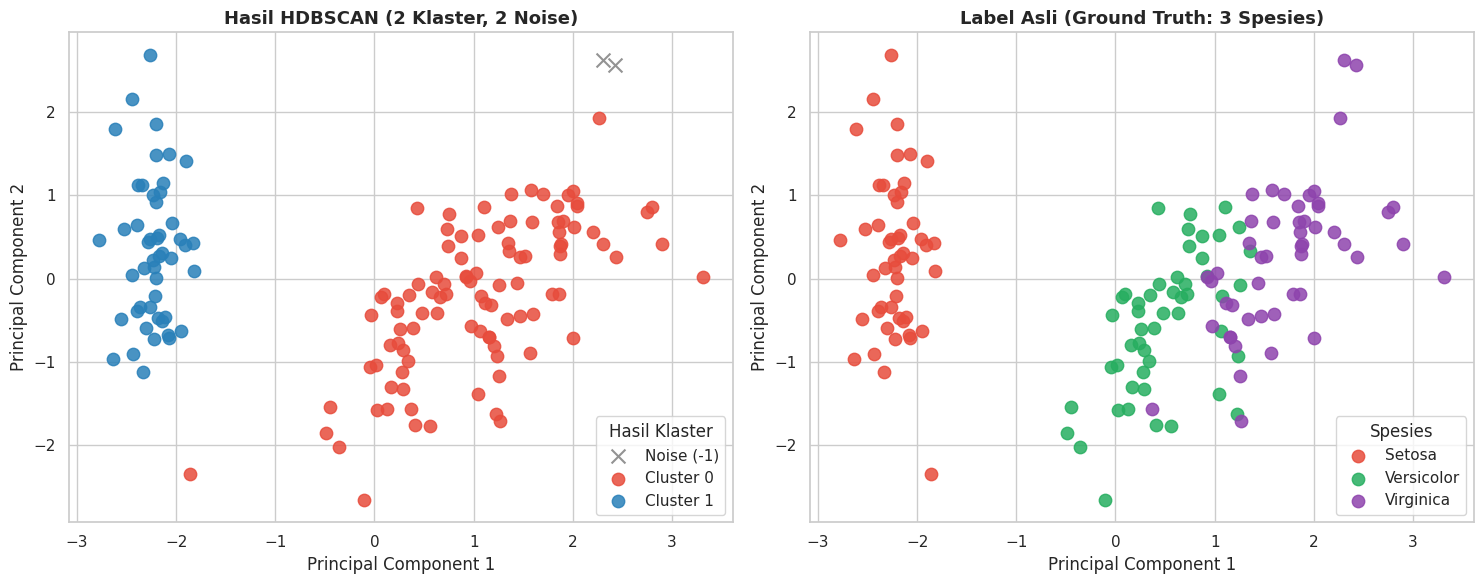


Tabel Kontinjensi (Label Asli vs Prediksi HDBSCAN):
Klaster HDBSCAN  -1   0   1
Label Asli                 
setosa            0   1  49
versicolor        0  50   0
virginica         2  48   0


In [7]:
# 5. Reduksi dimensi ke 2D menggunakan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_iris['PCA1'] = X_pca[:, 0]
df_iris['PCA2'] = X_pca[:, 1]

# Visualisasi Komparasi Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Hasil Clustering HDBSCAN
colors = {-1: 'gray', 0: '#e74c3c', 1: '#2980b9'}
labels_map = {-1: 'Noise (-1)', 0: 'Cluster 0', 1: 'Cluster 1'}

for cl in sorted(unique_labels):
    subset = df_iris[df_iris['cluster_hdbscan'] == cl]
    axes[0].scatter(
        subset['PCA1'], subset['PCA2'],
        c=colors[cl],
        label=labels_map[cl],
        marker='x' if cl == -1 else 'o',
        s=80 if cl != -1 else 100,
        alpha=0.85
    )

axes[0].set_title(f'Hasil HDBSCAN ({n_clusters} Klaster, {n_noise} Noise)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend(title='Hasil Klaster')

# Subplot 2: Label Ground Truth (Spesies Asli)
species_colors = {'setosa': '#e74c3c', 'versicolor': '#27ae60', 'virginica': '#8e44ad'}
for sp in target_names:
    subset = df_iris[df_iris['species'] == sp]
    axes[1].scatter(
        subset['PCA1'], subset['PCA2'],
        c=species_colors[sp],
        label=sp.capitalize(),
        s=80,
        alpha=0.85
    )

axes[1].set_title('Label Asli (Ground Truth: 3 Spesies)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend(title='Spesies')

plt.tight_layout()
plt.show()

# Tabel Kontinjensi (Silang)
print("\nTabel Kontinjensi (Label Asli vs Prediksi HDBSCAN):")
print(pd.crosstab(df_iris['species'], df_iris['cluster_hdbscan'], rownames=['Label Asli'], colnames=['Klaster HDBSCAN']))